In [1]:
### Cell 1: Importing Libraries
# Import necessary libraries for data processing, visualization, and modeling
import pandas as pd  # Data manipulation
import matplotlib.pyplot as plt  # Data visualization
import re  # Regular expressions for text processing
import nltk  # Natural Language Toolkit for NLP tasks
import emoji  # Handling emojis in text data
import numpy as np  # Numerical computations
import seaborn as sns  # Advanced data visualization
from nltk.corpus import stopwords  # Stopwords for text processing
from nltk.tokenize import word_tokenize  # Tokenization of text
from nltk.stem import PorterStemmer, WordNetLemmatizer  # Stemming and Lemmatization
from sklearn.feature_extraction.text import TfidfVectorizer  # TF-IDF feature extraction
from sklearn.linear_model import LogisticRegression  # Logistic Regression model
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc  # Evaluation metrics
from sklearn.model_selection import GridSearchCV, learning_curve  # Model selection and learning curve analysis
import joblib  # Model saving/loading
from wordcloud import WordCloud  # Generating word clouds
from collections import Counter  # Counting word occurrences

In [2]:
### Cell 2: Loading CSV Files
# Define the base path to Kaggle dataset
base_path = "/kaggle/input/ai-2-deep-learning-for-nlp-homework-1"

# Dictionary containing paths to datasets
datasets = {
    "train": f"{base_path}/train_dataset.csv",
    "val": f"{base_path}/val_dataset.csv",
    "test": f"{base_path}/test_dataset.csv"
}

# Load datasets into a dictionary
data = {name: pd.read_csv(path) for name, path in datasets.items()}

In [3]:
### Cell 3: Exploratory Data Analysis (EDA)
# Display basic dataset information
for name, df in data.items():
    print(f"\n🔹 {name.capitalize()} Dataset:")
    print(df.head(), "\n")  # Show first 5 rows
    print(f"🔹 {name} dataset size: {df.shape}")  # Show dataset dimensions
    print(f"🔹 Missing values: {df.isnull().sum().sum()}")  # Count missing values
    print(f"🔹 Duplicate tweets: {df.duplicated(subset=['Text']).sum()}")  # Count duplicate tweets


🔹 Train Dataset:
       ID                                               Text  Label
0  189385      @whoisralphie dude  I'm so bummed ur leaving!      0
1   58036  oh my god, a severed foot was foun in a wheely...      0
2  190139  I end up &quot;dog dialing&quot; sumtimes. Wha...      1
3   99313                         @_rachelx meeeee toooooo!       0
4  157825  I was hoping I could stay home and work today,...      0 

🔹 train dataset size: (148388, 3)
🔹 Missing values: 0
🔹 Duplicate tweets: 0

🔹 Val Dataset:
       ID                                               Text  Label
0  187062  @NatexTheGreat heyheyhey maybe i will  get the...      0
1  168997  @molliesmummy Work? Work was crap. I missed yo...      0
2  194461  Want: Trip to Boston next month. Need: Addit'l...      1
3  165442                        first day starts tomorrow!       1
4   34853  @goodforyoursoul 8 course fish in Little Saigo...      1 

🔹 val dataset size: (42396, 3)
🔹 Missing values: 0
🔹 Duplicate tweets:

In [4]:
### Cell 4: Label Distribution in Training Dataset
# Display class distribution in the training dataset
print("\n🔹 Label distribution in the training dataset:")
print(data["train"]["Label"].value_counts(normalize=True))


🔹 Label distribution in the training dataset:
Label
1    0.500013
0    0.499987
Name: proportion, dtype: float64


In [5]:
### Cell 5: Text Preprocessing
# Download necessary NLTK datasets
!unzip /usr/share/nltk_data/corpora/wordnet.zip -d /usr/share/nltk_data/corpora/

# Initialize text processing tools
lemmatizer = WordNetLemmatizer()
stemmer = PorterStemmer()
stop_words = set(stopwords.words("english"))

# Regular expressions for text cleaning
REPEATED_CHARS_PATTERN = re.compile(r"(.)\1{2,}", re.DOTALL)  # Detects repeated characters (e.g., "sooo" -> "so")
URL_PATTERN = re.compile(r"http\S+|www\S+|https\S+")  # Removes URLs
MENTIONS_PATTERN = re.compile(r"@\w+")  # Removes Twitter mentions (e.g., "@user")
HASHTAG_PATTERN = re.compile(r"#(\w+)")  # Keeps the word inside the hashtag while removing "#"
NUMERIC_PATTERN = re.compile(r"\b\d+\b")  # Removes standalone numbers
PUNCTUATION_PATTERN = re.compile(r"[^\w\s]")  # Removes punctuation
NON_ALPHABETIC_PATTERN = re.compile(r"[^a-z\s]")  # Removes non-alphabetic characters

# Dictionary for slang/acronyms
slang_dict = {
    "idk": "i do not know",
    "btw": "by the way",
    "lol": "laughing out loud",
    "brb": "be right back",
    "lmao": "laughing my ass off",
    "omg": "oh my god",
    "smh": "shaking my head",
    "wtf": "what the f***",
}

# Function to clean and preprocess text
def preprocess_text(text):
    text = text.lower()  # Convert text to lowercase
    text = URL_PATTERN.sub("", text)  # Remove URLs
    text = MENTIONS_PATTERN.sub("", text)  # Remove mentions (@username)
    text = HASHTAG_PATTERN.sub(r"\1", text)  # Remove '#' but keep the word
    text = NUMERIC_PATTERN.sub("", text)  # Remove numeric values
    text = emoji.demojize(text, delimiters=(" ", " "))  # Convert emojis to text representation
    text = PUNCTUATION_PATTERN.sub("", text)  # Remove punctuation
    text = REPEATED_CHARS_PATTERN.sub(r"\1", text)  # Replace repeated characters (e.g., "hellooo" → "hello")
    
    tokens = word_tokenize(text)  # Tokenize text into words
    # Replace slang words with their expanded form
    tokens = [slang_dict[word] if word in slang_dict else word for word in tokens]
    # Apply stemming and lemmatization while filtering out stopwords
    processed_tokens = [lemmatizer.lemmatize(stemmer.stem(word)) for word in tokens if word not in stop_words]
    
    return " ".join(processed_tokens)  # Return cleaned text as a single string

# Apply preprocessing to all datasets
for df in data.values():
    df["clean_text"] = df["Text"].apply(preprocess_text)


Archive:  /usr/share/nltk_data/corpora/wordnet.zip
   creating: /usr/share/nltk_data/corpora/wordnet/
  inflating: /usr/share/nltk_data/corpora/wordnet/lexnames  
  inflating: /usr/share/nltk_data/corpora/wordnet/data.verb  
  inflating: /usr/share/nltk_data/corpora/wordnet/index.adv  
  inflating: /usr/share/nltk_data/corpora/wordnet/adv.exc  
  inflating: /usr/share/nltk_data/corpora/wordnet/index.verb  
  inflating: /usr/share/nltk_data/corpora/wordnet/cntlist.rev  
  inflating: /usr/share/nltk_data/corpora/wordnet/data.adj  
  inflating: /usr/share/nltk_data/corpora/wordnet/index.adj  
  inflating: /usr/share/nltk_data/corpora/wordnet/LICENSE  
  inflating: /usr/share/nltk_data/corpora/wordnet/citation.bib  
  inflating: /usr/share/nltk_data/corpora/wordnet/noun.exc  
  inflating: /usr/share/nltk_data/corpora/wordnet/verb.exc  
  inflating: /usr/share/nltk_data/corpora/wordnet/README  
  inflating: /usr/share/nltk_data/corpora/wordnet/index.sense  
  inflating: /usr/share/nltk_data

In [6]:
### Cell 6: Dataset Distribution Analysis
# Calculate and display dataset proportions
total_samples = sum(len(df) for df in data.values())

# Print dataset distribution information
print("\n🔹 Dataset Distribution:")
for name, df in data.items():
    # Calculate the percentage of samples in each dataset partition
    percentage = (len(df) / total_samples) * 100
    # Print the dataset name, number of samples, and percentage of total samples
    print(f"{name.capitalize()} set: {len(df)} samples ({percentage:.2f}%)")


🔹 Dataset Distribution:
Train set: 148388 samples (70.00%)
Val set: 42396 samples (20.00%)
Test set: 21199 samples (10.00%)


/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1765: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  order = pd.unique(vector)


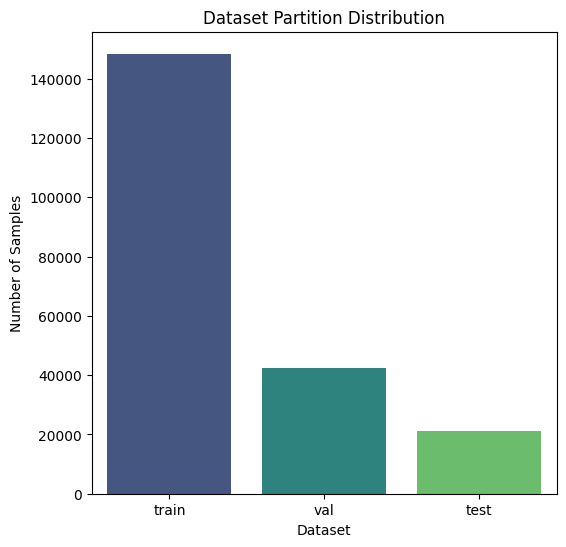

In [7]:
### Cell 7: Dataset Partition Visualization
# Plot dataset sizes
plt.figure(figsize=(6, 6))  # Set figure size

# Plot the number of samples in each dataset partition (train, test, validation)
sns.barplot(x=list(data.keys()), y=[len(df) for df in data.values()], palette="viridis")

# Label the axes
plt.xlabel("Dataset")  # X-axis label
plt.ylabel("Number of Samples")  # Y-axis label

# Set the title of the plot
plt.title("Dataset Partition Distribution")

# Display the plot
plt.show()

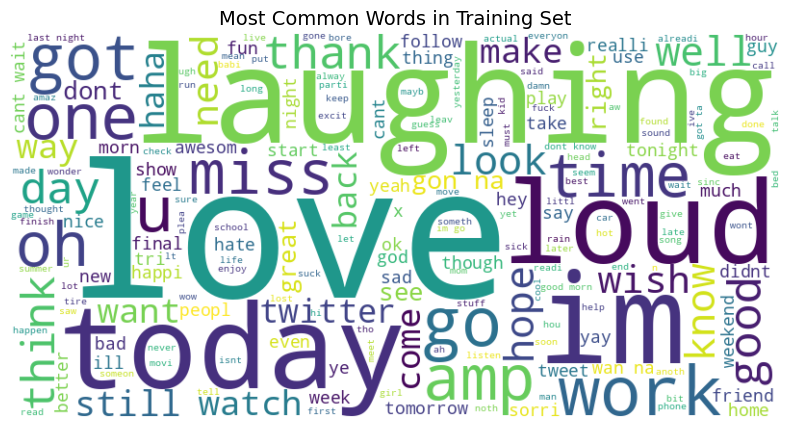

In [8]:
### Cell 8: Word Cloud for Positive & Negative Reviews
# Function to generate a word cloud
def plot_wordcloud(texts, title):
    # Combine all text samples into a single string
    text = " ".join(texts)

    # Generate a word cloud image with specified dimensions and background color
    wordcloud = WordCloud(width=800, height=400, background_color="white").generate(text)

    # Plot the generated word cloud
    plt.figure(figsize=(10, 5))  # Set figure size
    plt.imshow(wordcloud, interpolation="bilinear")  # Display the word cloud image
    plt.axis("off")  # Remove axes for better visualization
    plt.title(title, fontsize=14)  # Set title for the plot
    plt.show()  # Show the plot

# Generate a word cloud for the cleaned text in the training dataset
plot_wordcloud(data["train"]["clean_text"], "Most Common Words in Training Set")

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


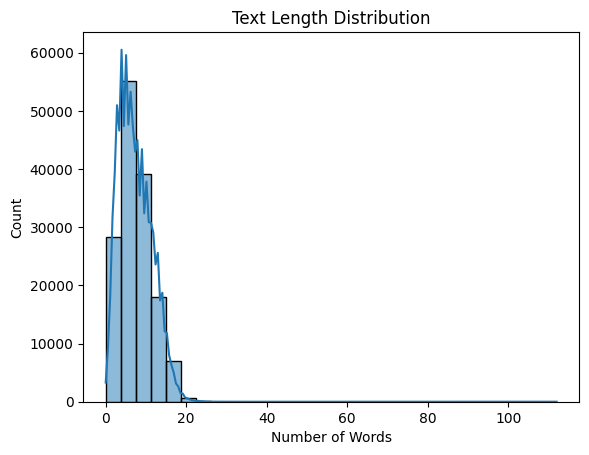

In [9]:
### Cell 9: Text Length Distribution
# Compute the length of each cleaned text in words  
data["train"]["text_length"] = data["train"]["clean_text"].apply(lambda x: len(x.split()))  

# Plot a histogram to visualize the distribution of text lengths  
sns.histplot(data["train"]["text_length"], bins=30, kde=True)  

# Set labels and title for the plot  
plt.xlabel("Number of Words")  # X-axis represents the number of words in each text  
plt.ylabel("Count")  # Y-axis represents the number of tweets with a given word count  
plt.title("Text Length Distribution")  # Title of the plot  

# Display the plot  
plt.show()  

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1765: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  order = pd.unique(vector)


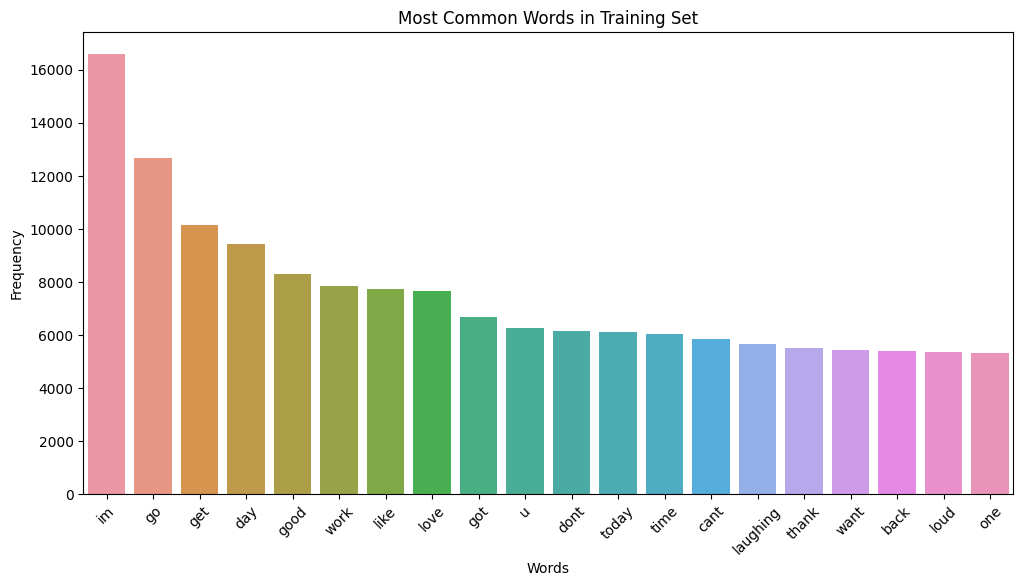

In [10]:
### Cell 10: Most Frequent Words Bar Plot
# Count the frequency of each word in the cleaned training text
word_counts = Counter(" ".join(data["train"]["clean_text"]).split())

# Retrieve the 20 most common words and their frequencies
common_words = word_counts.most_common(20)

# Set the figure size for better visualization
plt.figure(figsize=(12,6))

# Create a bar plot for the most common words
sns.barplot(x=[word[0] for word in common_words], y=[word[1] for word in common_words])

# Rotate x-axis labels for better readability
plt.xticks(rotation=45)

# Label the axes
plt.xlabel("Words")
plt.ylabel("Frequency")

# Set the title of the plot
plt.title("Most Common Words in Training Set")

# Display the plot
plt.show()


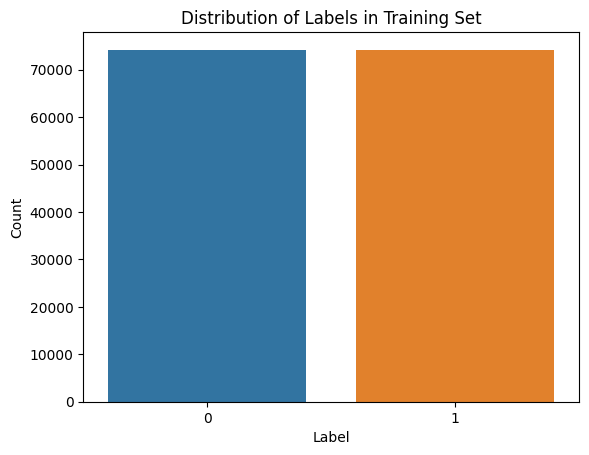

In [11]:
### Cell 11: Label Distribution in Training Set
# Create a count plot to visualize the distribution of labels in the training set
sns.countplot(x=data["train"]["Label"])

# Label the x-axis
plt.xlabel("Label")

# Label the y-axis
plt.ylabel("Count")

# Set the title of the plot
plt.title("Distribution of Labels in Training Set")

# Display the plot
plt.show()

In [12]:
### Cell 12: TF-IDF Vectorization
# Convert text data into numerical features using TF-IDF vectorizer
vectorizer = TfidfVectorizer(
    max_features=10000,  # Limit the vocabulary size to the 10,000 most important features
    ngram_range=(1,2),   # Consider both unigrams and bigrams
    min_df=2,            # Ignore terms that appear in fewer than 2 documents
    max_df=0.95          # Ignore terms that appear in more than 95% of documents (likely stopwords)
)

# Fit and transform the training text data into a TF-IDF representation
X_train_tfidf = vectorizer.fit_transform(data["train"]["clean_text"])

# Transform validation and test sets using the same vectorizer
X_val_tfidf = vectorizer.transform(data["val"]["clean_text"])
X_test_tfidf = vectorizer.transform(data["test"]["clean_text"])

# Extract labels for training and validation sets
y_train = data["train"]["Label"]
y_val = data["val"]["Label"]

In [13]:
### Cell 13: Logistic Regression with Grid Search
# Define a hyperparameter grid for tuning the Logistic Regression model
param_grid = {
    "C": [0.01, 0.1, 1, 10],  # Regularization strength values to test
    "penalty": ["l1", "l2"]   # Different types of regularization (Lasso and Ridge)
}

# Initialize a GridSearchCV object to find the best hyperparameters
model = GridSearchCV(
    LogisticRegression(solver="liblinear", max_iter=1000, random_state=42),  
    param_grid,  # Pass the hyperparameter grid
    cv=3,        # Use 3-fold cross-validation for evaluation
    scoring='accuracy'  # Optimize for classification accuracy
)

# Fit the model using training data
model.fit(X_train_tfidf, y_train)

GridSearchCV(cv=3,
             estimator=LogisticRegression(max_iter=1000, random_state=42,
                                          solver='liblinear'),
             param_grid={'C': [0.01, 0.1, 1, 10], 'penalty': ['l1', 'l2']},
             scoring='accuracy')

In [14]:
### Cell 14: Saving the Best Model
# Retrieve the best model found during GridSearchCV
best_model = model.best_estimator_

# Save the best model to a file using joblib for later use
joblib.dump(best_model, "best_logistic_regression.pkl")

['best_logistic_regression.pkl']

In [15]:
### Cell 15: Predictions
# Generate predictions on the training set using the best model
y_pred_train = model.best_estimator_.predict(X_train_tfidf)

# Generate predictions on the validation set using the best model
y_pred_val = model.best_estimator_.predict(X_val_tfidf)

In [16]:
### Cell 16: Performance Evaluation
# Evaluate the model's performance on the training set
print("\n🔹 Train Performance:")
print(classification_report(y_train, y_pred_train))

# Evaluate the model's performance on the validation set
print("\n🔹 Validation Performance:")
print(classification_report(y_val, y_pred_val))


🔹 Train Performance:
              precision    recall  f1-score   support

           0       0.81      0.78      0.79     74192
           1       0.79      0.82      0.80     74196

    accuracy                           0.80    148388
   macro avg       0.80      0.80      0.80    148388
weighted avg       0.80      0.80      0.80    148388


🔹 Validation Performance:
              precision    recall  f1-score   support

           0       0.79      0.76      0.77     21197
           1       0.77      0.79      0.78     21199

    accuracy                           0.78     42396
   macro avg       0.78      0.78      0.78     42396
weighted avg       0.78      0.78      0.78     42396



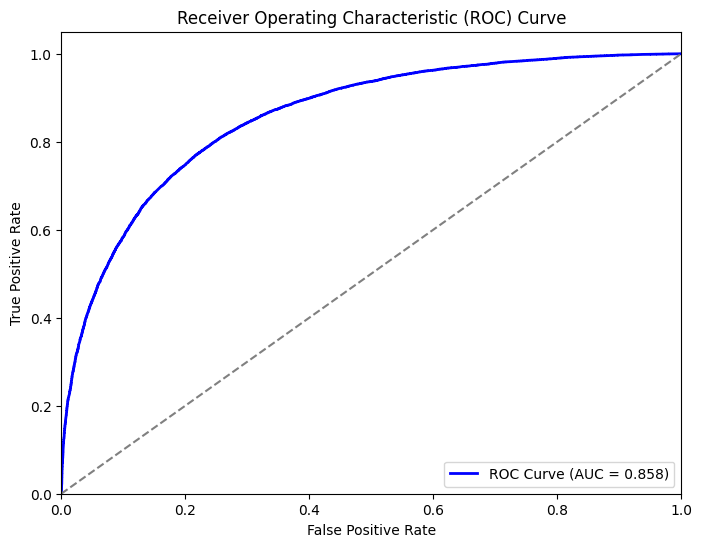

In [17]:
### Cell 17: ROC Curve Plotting
# Obtain the predicted probabilities for the positive class (class 1)
y_scores = model.best_estimator_.predict_proba(X_val_tfidf)[:, 1]  

# Compute the False Positive Rate (FPR) and True Positive Rate (TPR) for different thresholds
fpr, tpr, _ = roc_curve(y_val, y_scores)

# Calculate the Area Under the Curve (AUC) for performance evaluation
roc_auc = auc(fpr, tpr)

# Plot the ROC Curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color="blue", lw=2, label=f"ROC Curve (AUC = {roc_auc:.3f})")

# Plot a diagonal reference line representing a random classifier
plt.plot([0, 1], [0, 1], color="gray", linestyle="--")  

# Set plot limits for better visualization
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])

# Label axes and title
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC) Curve")

# Display legend and show the plot
plt.legend(loc="lower right")
plt.show()

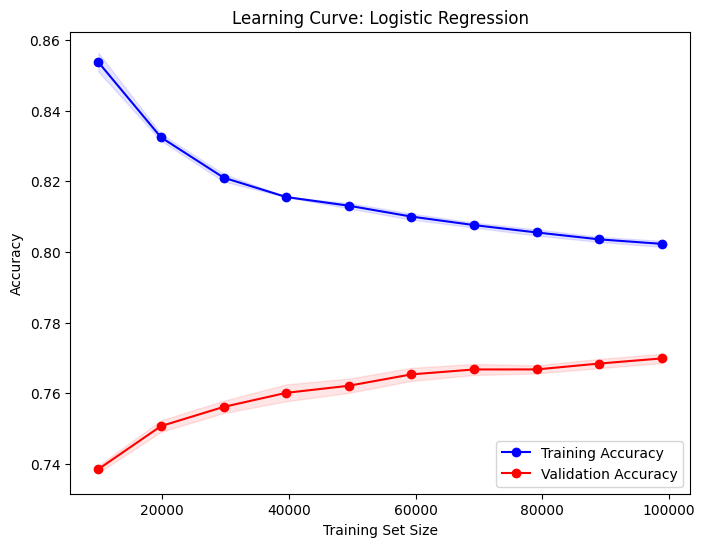

In [18]:
### Cell 18: Learning Curve
# Define the training set sizes to be used for model training
train_sizes, train_scores, val_scores = learning_curve(
    model.best_estimator_, X_train_tfidf, y_train, cv=3, scoring="accuracy", 
    n_jobs=-1, train_sizes=np.linspace(0.1, 1.0, 10)
)

# Compute the mean and standard deviation of training and validation scores
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)
val_std = np.std(val_scores, axis=1)

# Plot the Learning Curve
plt.figure(figsize=(8, 6))

# Plot training accuracy with confidence interval
plt.plot(train_sizes, train_mean, "o-", color="blue", label="Training Accuracy")
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, color="blue", alpha=0.1)

# Plot validation accuracy with confidence interval
plt.plot(train_sizes, val_mean, "o-", color="red", label="Validation Accuracy")
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, color="red", alpha=0.1)

# Set axis labels and title
plt.xlabel("Training Set Size")
plt.ylabel("Accuracy")
plt.title("Learning Curve: Logistic Regression")

# Display legend and show the plot
plt.legend(loc="lower right")
plt.show()

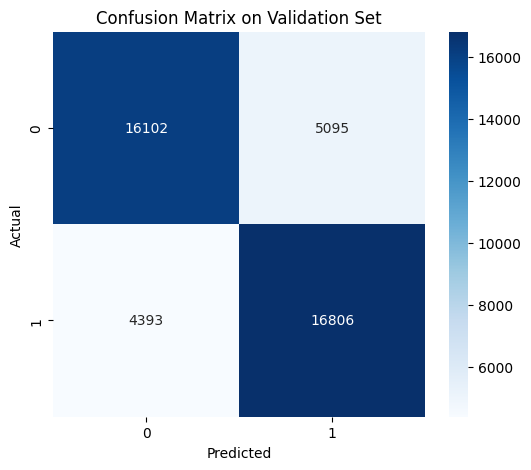

In [19]:
### Cell 19: Confusion Matrix
# Create a figure with a specified size
plt.figure(figsize=(6,5))

# Plot the confusion matrix as a heatmap
sns.heatmap(confusion_matrix(y_val, y_pred_val), annot=True, fmt='d', cmap='Blues')

# Set axis labels and title
plt.xlabel("Predicted")  # X-axis represents predicted labels
plt.ylabel("Actual")     # Y-axis represents actual labels
plt.title("Confusion Matrix on Validation Set")

# Display the plot
plt.show()

In [20]:
### Cell 20: Creating submission.csv
# Generate predictions on the test dataset
test_preds = best_model.predict(X_test_tfidf)

# Create a DataFrame with test IDs and corresponding predictions
submission = pd.DataFrame({"ID": data["test"]["ID"], "Label": test_preds})

# Save the predictions to a CSV file for submission
submission.to_csv("submission.csv", index=False)

# Print confirmation message
print("\n🔹 Submission file saved as submission.csv")


🔹 Submission file saved as submission.csv
